In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [21]:
df = pd.read_csv(r"/Users/yusrausman/Downloads/teaching_prices_clean .csv")
df.head()

,date,item,city,price,unit,data_label
0,01/01/2026,Staple A,City 1,101.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
1,01/01/2026,Staple A,City 2,107.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
2,01/01/2026,Oil B,City 1,298.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
3,01/01/2026,Oil B,City 2,304.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
4,01/01/2026,Pulse C,City 1,200.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...


In [23]:
print(df.head())
print(df.info())
print(df.columns)
print(df.isnull().sum())

         date      item    city  price                       unit  \
0  01/01/2026  Staple A  City 1  101.0  PKR per kg (illustrative)   
1  01/01/2026  Staple A  City 2  107.0  PKR per kg (illustrative)   
2  01/01/2026     Oil B  City 1  298.0  PKR per kg (illustrative)   
3  01/01/2026     Oil B  City 2  304.0  PKR per kg (illustrative)   
4  01/01/2026   Pulse C  City 1  200.0  PKR per kg (illustrative)   

                                          data_label  
0  ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...  
1  ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...  
2  ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...  
3  ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...  
4  ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        96 non-null     object 
 1   item        96 non-null  

In [25]:
item_statistics = df.groupby("item")["price"].agg(
    Mean="mean",
    Median="median"
)

print(item_statistics)

                   Mean  Median
item                           
Oil B        324.833333  324.00
Pulse C      205.916667  206.00
Staple A     111.166667  111.75
Sweetener D  166.750000  166.75


In [29]:
df["date"] = pd.to_datetime(df["date"],format = 'mixed')

df = df.sort_values("date")

percentage_change = df.groupby("item")["price"].agg(
    First="first",
    Last="last"
)

percentage_change["Percentage Change"] = (
    (percentage_change["Last"] - percentage_change["First"])
    / percentage_change["First"]
) * 100

print(percentage_change)


             First   Last  Percentage Change
item                                        
Oil B        298.0  344.0          15.436242
Pulse C      200.0  211.0           5.500000
Staple A     101.0  116.0          14.851485
Sweetener D  149.0  180.0          20.805369


In [31]:
item_name = "ENTER_ITEM_NAME"

selected_item = df[df["item"] == item_name]

mean_with_flag = selected_item["price"].mean()
median_with_flag = selected_item["price"].median()

print("Mean with flagged value:", mean_with_flag)
print("Median with flagged value:", median_with_flag)

Mean with flagged value: nan
Median with flagged value: nan


In [35]:
print(df.columns)
print(df['item'].unique())

Index(['date', 'item', 'city', 'price', 'unit', 'data_label'], dtype='object')
['Staple A' 'Oil B' 'Pulse C' 'Sweetener D']


In [45]:
print(selected_item.shape)
print(selected_item.head())
print(selected_item.columns)


(0, 6)
Empty DataFrame
Columns: [date, item, city, price, unit, data_label]
Index: []
Index(['date', 'item', 'city', 'price', 'unit', 'data_label'], dtype='object')


In [53]:
selected_item = df[df['item'] == 'Staple A']
print(selected_item.shape)
selected_item.head()


(24, 6)


,date,item,city,price,unit,data_label
0,2026-01-01,Staple A,City 1,101.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
1,2026-01-01,Staple A,City 2,107.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
17,2026-01-15,Staple A,City 2,109.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
16,2026-01-15,Staple A,City 1,103.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
25,2026-01-22,Staple A,City 2,112.5,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...


In [57]:
mean_with_all =selected_item['price'].mean()
median_with_all =selected_item['price'].median()
print("mean with all values:",mean_with_all)
print("median with all values:",median_with_all)

mean with all values: 111.16666666666667
median with all values: 111.75


In [61]:
print(selected_item['price'].describe())

count     24.000000
mean     111.166667
std        6.151470
min       99.500000
25%      106.875000
50%      111.750000
75%      114.875000
max      122.000000
Name: price, dtype: float64


In [65]:
selected_item.sort_values('price')

,date,item,city,price,unit,data_label
8,2026-08-01,Staple A,City 1,99.5,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
0,2026-01-01,Staple A,City 1,101.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
16,2026-01-15,Staple A,City 1,103.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
32,2026-01-29,Staple A,City 1,105.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
9,2026-08-01,Staple A,City 2,105.5,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
24,2026-01-22,Staple A,City 1,106.5,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
1,2026-01-01,Staple A,City 2,107.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
48,2026-12-02,Staple A,City 1,107.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
40,2026-05-02,Staple A,City 1,108.5,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...
17,2026-01-15,Staple A,City 2,109.0,PKR per kg (illustrative),ILLUSTRATIVE TEACHING DATA - NOT ACTUAL PBS OB...


In [69]:
Q1 =selected_item['price'].quantile(0.25)
Q3 =selected_item['price'].quantile(0.75)

IQR = Q3-Q1

lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR

print('lower limit:',lower_limit)
print('upper limit:',upper_limit)

lower limit: 94.875
upper limit: 126.875


In [83]:
outliers = selected_item[
    (selected_item["price"] < lower_limit) |
    (selected_item["price"] > upper_limit)
]

print("Number of outliers:", len(outliers))
print(outliers)

Number of outliers: 0
Empty DataFrame
Columns: [date, item, city, price, unit, data_label]
Index: []


In [85]:
without_outliers = selected_item[
    (selected_item["price"] >= lower_limit) &
    (selected_item["price"] <= upper_limit)
]

comparison_stats = pd.DataFrame({
    "Statistic": ["Mean", "Median"],
    "With Outliers": [
        selected_item["price"].mean(),
        selected_item["price"].median()
    ],
    "Without Outliers": [
        without_outliers["price"].mean(),
        without_outliers["price"].median()
    ]
})

print(comparison_stats)

  Statistic  With Outliers  Without Outliers
0      Mean     111.166667        111.166667
1    Median     111.750000        111.750000


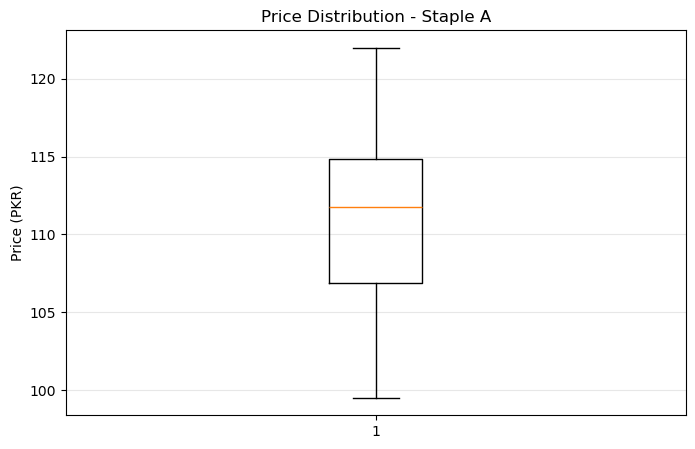

In [87]:
plt.figure(figsize=(8, 5))

plt.boxplot(selected_item["price"].dropna())

plt.title("Price Distribution - Staple A")
plt.ylabel("Price (PKR)")
plt.grid(axis="y", alpha=0.3)

plt.show()

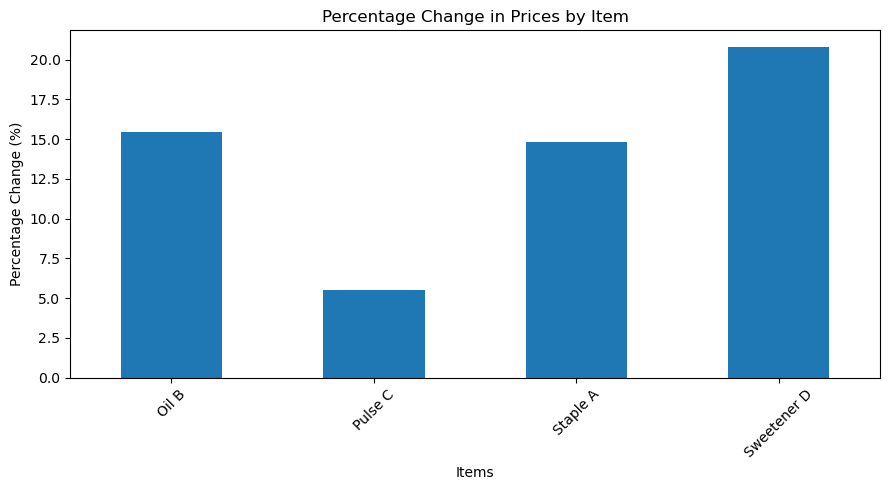

In [89]:
plt.figure(figsize=(9, 5))

percentage_change["Percentage Change"].plot(
    kind="bar"
)

plt.title("Percentage Change in Prices by Item")
plt.xlabel("Items")
plt.ylabel("Percentage Change (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [91]:
outliers.to_csv("detected_outliers.csv", index=False)

comparison_stats.to_csv(
    "outlier_statistics_comparison.csv",
    index=False
)

print(" results saved successfully!")

 results saved successfully!


In [75]:
item_statistics.to_csv("item_statistics.csv")

percentage_change.to_csv("percentage_change.csv")



In [77]:
print(item_statistics)
print(percentage_change)

                   Mean  Median
item                           
Oil B        324.833333  324.00
Pulse C      205.916667  206.00
Staple A     111.166667  111.75
Sweetener D  166.750000  166.75
             First   Last  Percentage Change
item                                        
Oil B        298.0  344.0          15.436242
Pulse C      200.0  211.0           5.500000
Staple A     101.0  116.0          14.851485
Sweetener D  149.0  180.0          20.805369


In [79]:
city_prices = df.sort_values('date').groupby(
    ['item','city']
)['price'].agg(
    first='first',
    last='last'
)
city_prices['percentage change'] =(
    (city_prices['last'] - city_prices['first'])
    /city_prices['first']
)*100
print(city_prices)


                    first   last  percentage change
item        city                                   
Oil B       City 1  298.0  338.0          13.422819
            City 2  304.0  344.0          13.157895
Pulse C     City 1  200.0  205.0           2.500000
            City 2  206.0  211.0           2.427184
Staple A    City 1  101.0  116.0          14.851485
            City 2  107.0  122.0          14.018692
Sweetener D City 1  149.0  174.0          16.778523
            City 2  155.0  180.0          16.129032


In [81]:
city_prices.to_csv("city_wise_percentage_change.csv")
print("city-wise results saved successfully!")

city-wise results saved successfully!
